# Guven

1. Cue-aligned time-frequency maps.
2. Cue / impulse 1 band time courses.
3. Rotation 0° / 30° / 60°: all-line mean power.


In [1]:
import importlib
import pickle
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

# The plotting code lives in the repository's functions/ folder, next to this notebook's folder.
sys.path.insert(0, str(Path.cwd().parent))
from functions.tw_funcs import tw_plot_funcs as plots
plots = importlib.reload(plots)  # pick up edits to tw_plot_funcs without restarting the kernel

In [2]:
from scipy.io import loadmat
from itertools import combinations

# Data and figures are not in the repository: set this to their folder on your machine.
DATA_ROOT = Path('/Volumes/T7/travelling_waves')

RESULT_DIR = DATA_ROOT / 'tw/result/guven_fft'
BEHAVIOR_DIR = DATA_ROOT / 'guven_data/Raw_Data'
FIG_DIR = DATA_ROOT / 'tw/result/figs/guven'
CORRECT_ONLY = False
FREQ_BANDS = [(2,6,'theta'), (8,12,'alpha'), (14,30,'beta')]
BAND_YLIM = (-.15, .15)
# Cluster permutation tests: number of permutations, random seed, significance level.
N_PERMUTATIONS = 5000
SEED = 42
ALPHA = 0.05
# Task events: (onset s, duration s, label).
EVENTS = [(0, .250, 'target'), (.75, .200, 'cue'), (1.85, .100, 'impulse 1'),
          (2.45, .200, 'rotation'), (3.55, .100, 'impulse 2'), (4.15, .200, 'probe')]
PLOT_WINDOWS = {
    'cue': dict(t_start=.5, t_stop=2.75, time_zero=.75),
    'impulse': dict(t_start=1.6, t_stop=3.05, time_zero=1.85),
}


TF_COLOR_LIMIT = .05
ROTATIONS=(0,30,60)
ROTATION_TESTS=list(combinations(ROTATIONS,2))


In [3]:
def session_ids(path):
    match = re.search(r'sub(\d+)_session(\d+)', path.name)
    return int(match[1]), int(match[2])

def load_pickle(path):
    with path.open('rb') as stream:
        return pickle.load(stream)

def read_trials(path):
    """One row per trial of one session: behavior (from the .mat file) and exclusion flags."""
    subject, session = session_ids(path)
    data = load_pickle(path)
    behavior_path = (BEHAVIOR_DIR / f'Ppt_{subject}' / 'Behavioural/Experiment'
                     / f'Results_Gen_2_Mental_Rotation_Experiment_EEG_{subject}_{session}_1.mat')
    behavior = np.asarray(loadmat(behavior_path, simplify_cells=True)['ResultMatrix'])
    return pd.DataFrame(dict(
        file=path, subject=subject, trial=np.arange(len(data['cue_loc'])),
        acc=behavior[:, 0].astype(int), rt=behavior[:, 1].astype(float),
        rotation=np.array([0, 30, 60])[behavior[:, 9].astype(int)-1],
        cue_left=np.asarray(data['cue_loc']) == 1,  # cue_loc 1 = left
        bad_epoch=np.asarray(data['is_bad_epoch'], bool)))

SESSION_PATHS = sorted(RESULT_DIR.glob('sub*_session*.pkl'))
trials = pd.concat([read_trials(path) for path in SESSION_PATHS], ignore_index=True)

kept = trials[~trials.bad_epoch]
if CORRECT_ONLY:
    kept = kept[kept.acc == 1]

In [4]:
# Group-level behaviour, each subject counts the same: one value per subject (RT: mean over
# retained trials; accuracy: over all trials, before trial filtering), then mean, SD (ddof=1)
# and SEM across subjects.
subject_behavior = pd.DataFrame({
    'RT (s)': kept.groupby('subject').rt.mean(),
    'Accuracy (%)': 100 * (trials.acc == 1).groupby(trials.subject).mean(),
})
group_summary = subject_behavior.agg(['count', 'mean', 'std', 'sem']).T
group_summary = group_summary.rename(columns={'count': 'n_subjects', 'std': 'sd'}).astype({'n_subjects': int})
display(group_summary.round(4))


,n_subjects,mean,sd,sem
RT (s),30,0.4704,0.0789,0.0144
Accuracy (%),30,82.1898,3.9113,0.7141


## Cue TF maps


[cue | fw | difference]
No significant clusters. Minimum-p cluster (not significant):
time=[850.0, 1000.0] ms, freq=[28.0, 30.0] Hz, p=0.2376


[cue | bw | difference]
time=[350.0, 750.0] ms, freq=[10.0, 12.0] Hz, p=0.004


[saved] /Volumes/T7/travelling_waves/tw/result/figs/guven/cue_fw_bw_tf_difference_0p5-2p75s_zero-0p75s.png


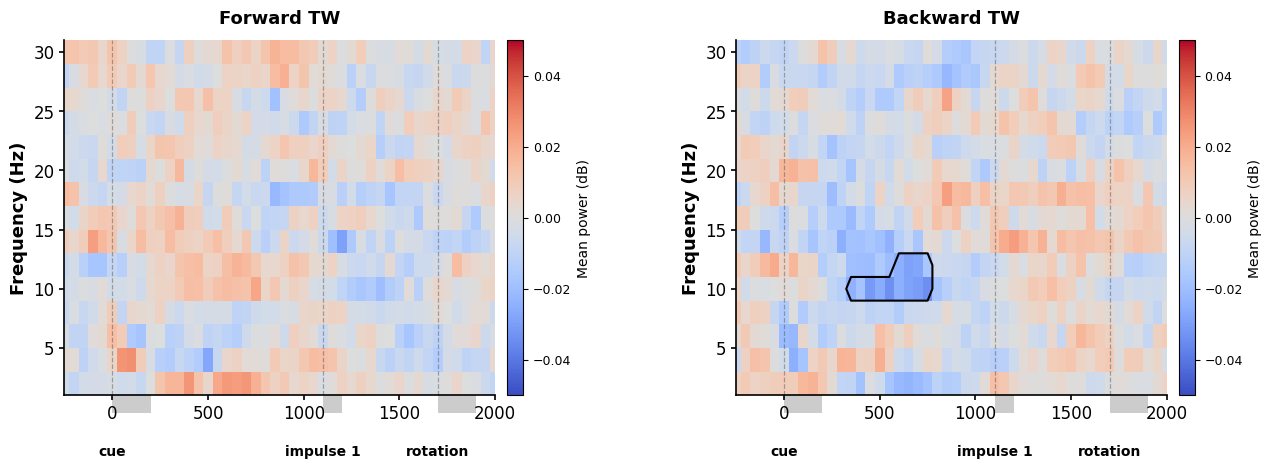

In [6]:
# Cue alignment: on cue-left trials the line order is reversed (flipped).
cue_maps = plots.average_maps(kept, flip='cue_left')
plots.plot_tf_maps(cue_maps, **PLOT_WINDOWS['cue'],
    color_limit=TF_COLOR_LIMIT,
    output_dir=FIG_DIR, name='cue', events=EVENTS, n_perm=N_PERMUTATIONS, seed=SEED, alpha=ALPHA);

## Cue 和 impulse 1 频段曲线


[cue | fw | alpha (8–12 Hz) | all]
No significant clusters. Minimum-p cluster (not significant):
time=[1300.0, 1400.0] ms, p=0.1146


[cue | bw | alpha (8–12 Hz) | all]
time=[350.0, 750.0] ms, p=0.003


[saved] /Volumes/T7/travelling_waves/tw/result/figs/guven/cue_fw_bw_bands_0p5-2p75s_zero-0p75s.png


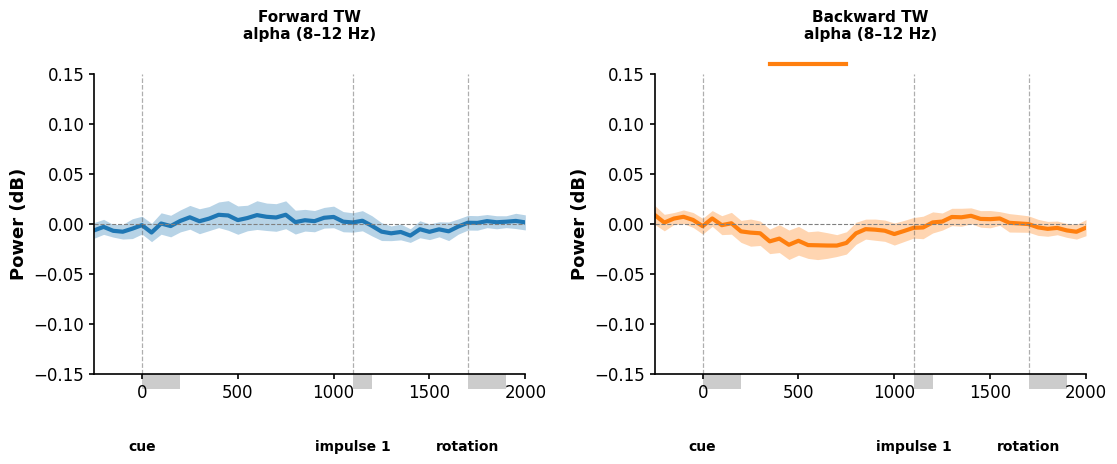

[impulse1 | fw | alpha (8–12 Hz) | all]
No significant clusters. Minimum-p cluster (not significant):
time=[200.0, 300.0] ms, p=0.0578


[impulse1 | bw | alpha (8–12 Hz) | all]
No significant clusters. Minimum-p cluster (not significant):
time=[850.0, 850.0] ms, p=0.5584
[saved] /Volumes/T7/travelling_waves/tw/result/figs/guven/impulse1_fw_bw_bands_1p6-3p05s_zero-1p85s.png


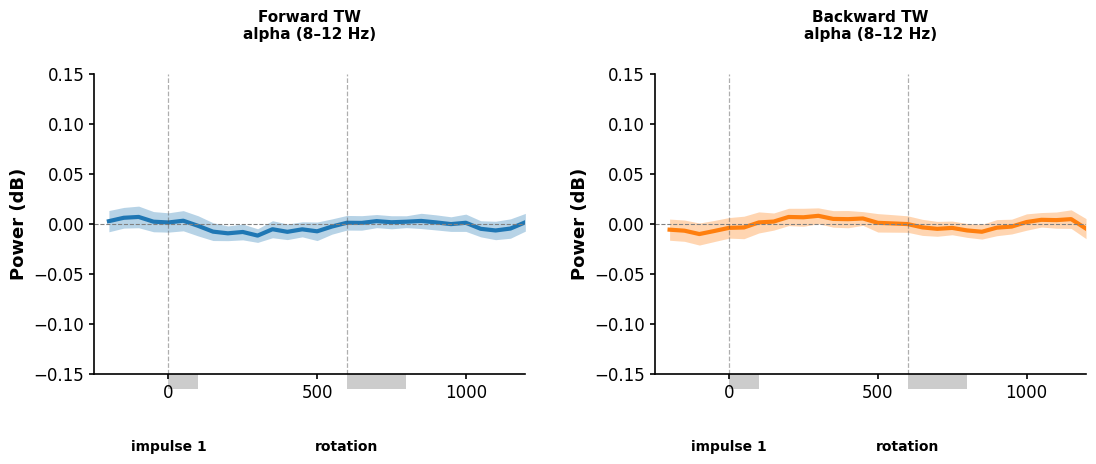

In [7]:
for name,window in [('cue',PLOT_WINDOWS['cue']),('impulse1',PLOT_WINDOWS['impulse'])]:
    plots.plot_band_timeseries(cue_maps,group='difference',
        freq_bands=[FREQ_BANDS[1]], layout='columns',**window,ylim=BAND_YLIM,
        output_dir=FIG_DIR,name=name,
        events=EVENTS, n_perm=N_PERMUTATIONS, seed=SEED, alpha=ALPHA);


[cue_beta | fw | beta (14–30 Hz) | all]
No significant clusters. Minimum-p cluster (not significant):
time=[300.0, 300.0] ms, p=0.6248


[cue_beta | bw | beta (14–30 Hz) | all]
time=[250.0, 450.0] ms, p=0.014
[saved] /Volumes/T7/travelling_waves/tw/result/figs/guven/cue_beta_fw_bw_bands_0p5-2p75s_zero-0p75s.png


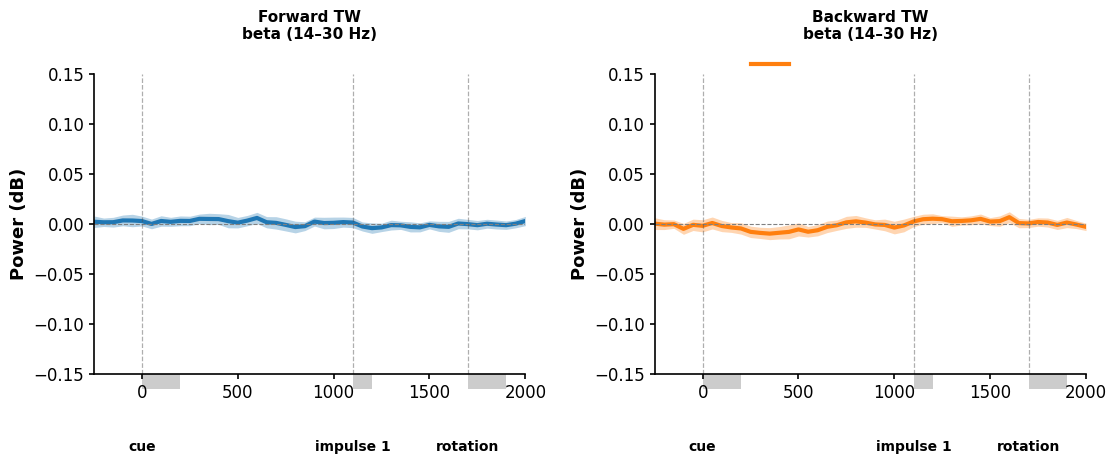

/Volumes/T7/travelling_waves/tw/decoding_gpu/uploads/functions/tw_funcs/tw_plot_funcs.py:145: RuntimeWarning: No clusters found, returning empty H0, clusters, and cluster_pv
  _, clusters, p_values, _ = permutation_cluster_1samp_test(


[impulse1_beta | fw | beta (14–30 Hz) | all]
No clusters found; no cluster time window or p-value to report.


[impulse1_beta | bw | beta (14–30 Hz) | all]
No significant clusters. Minimum-p cluster (not significant):
time=[100.0, 150.0] ms, p=0.1206
[saved] /Volumes/T7/travelling_waves/tw/result/figs/guven/impulse1_beta_fw_bw_bands_1p6-3p05s_zero-1p85s.png


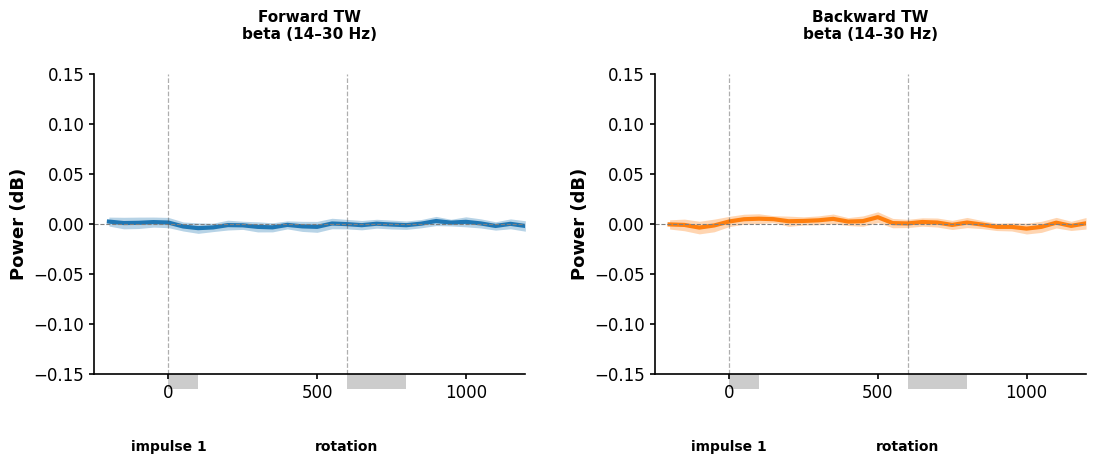

In [8]:
for name, window in [('cue', PLOT_WINDOWS['cue']), ('impulse1', PLOT_WINDOWS['impulse'])]:
    plots.plot_band_timeseries(cue_maps, group='difference',
        freq_bands=[FREQ_BANDS[2]], layout='columns', **window, ylim=BAND_YLIM,
        output_dir=FIG_DIR, name=f'{name}_beta',
        events=EVENTS, n_perm=N_PERMUTATIONS, seed=SEED, alpha=ALPHA);

## Rotation: all-line mean power (0° / 30° / 60°)


[rotation_selected_lines | fw | theta (2–6 Hz) | 0 − 30]
time=[1600.0, 2500.0] ms, p=0.0002, Bonferroni p=0.0006


[rotation_selected_lines | fw | theta (2–6 Hz) | 0 − 60]
time=[1650.0, 2150.0] ms, p=0.0002, Bonferroni p=0.0006


[rotation_selected_lines | fw | theta (2–6 Hz) | 30 − 60]
No significant clusters. Minimum-p cluster (not significant):
time=[2850.0, 2950.0] ms, p=0.0426, Bonferroni p=0.1278


[rotation_selected_lines | fw | alpha (8–12 Hz) | 0 − 30]
time=[1600.0, 2050.0] ms, p=0.0026, Bonferroni p=0.0078


[rotation_selected_lines | fw | alpha (8–12 Hz) | 0 − 60]
time=[1600.0, 2050.0] ms, p=0.0038, Bonferroni p=0.0114
[rotation_selected_lines | fw | alpha (8–12 Hz) | 30 − 60]
No clusters found; no cluster time window or p-value to report.


/Volumes/T7/travelling_waves/tw/decoding_gpu/uploads/functions/tw_funcs/tw_plot_funcs.py:145: RuntimeWarning: No clusters found, returning empty H0, clusters, and cluster_pv
  _, clusters, p_values, _ = permutation_cluster_1samp_test(


... (9 outputs left out)

[rotation_selected_lines | bw | beta (14–30 Hz) | 0 − 30]
No significant clusters. Minimum-p cluster (not significant):
time=[2050.0, 2100.0] ms, p=0.2248, Bonferroni p=0.6744
[rotation_selected_lines | bw | beta (14–30 Hz) | 0 − 60]
No clusters found; no cluster time window or p-value to report.


/Volumes/T7/travelling_waves/tw/decoding_gpu/uploads/functions/tw_funcs/tw_plot_funcs.py:145: RuntimeWarning: No clusters found, returning empty H0, clusters, and cluster_pv
  _, clusters, p_values, _ = permutation_cluster_1samp_test(


[rotation_selected_lines | bw | beta (14–30 Hz) | 30 − 60]
No significant clusters. Minimum-p cluster (not significant):
time=[2250.0, 2250.0] ms, p=0.5284, Bonferroni p=1


[saved] /Volumes/T7/travelling_waves/tw/result/figs/guven/rotation_selected_lines_fw_bw_bands_0p5-4p15s_zero-0p75s.png


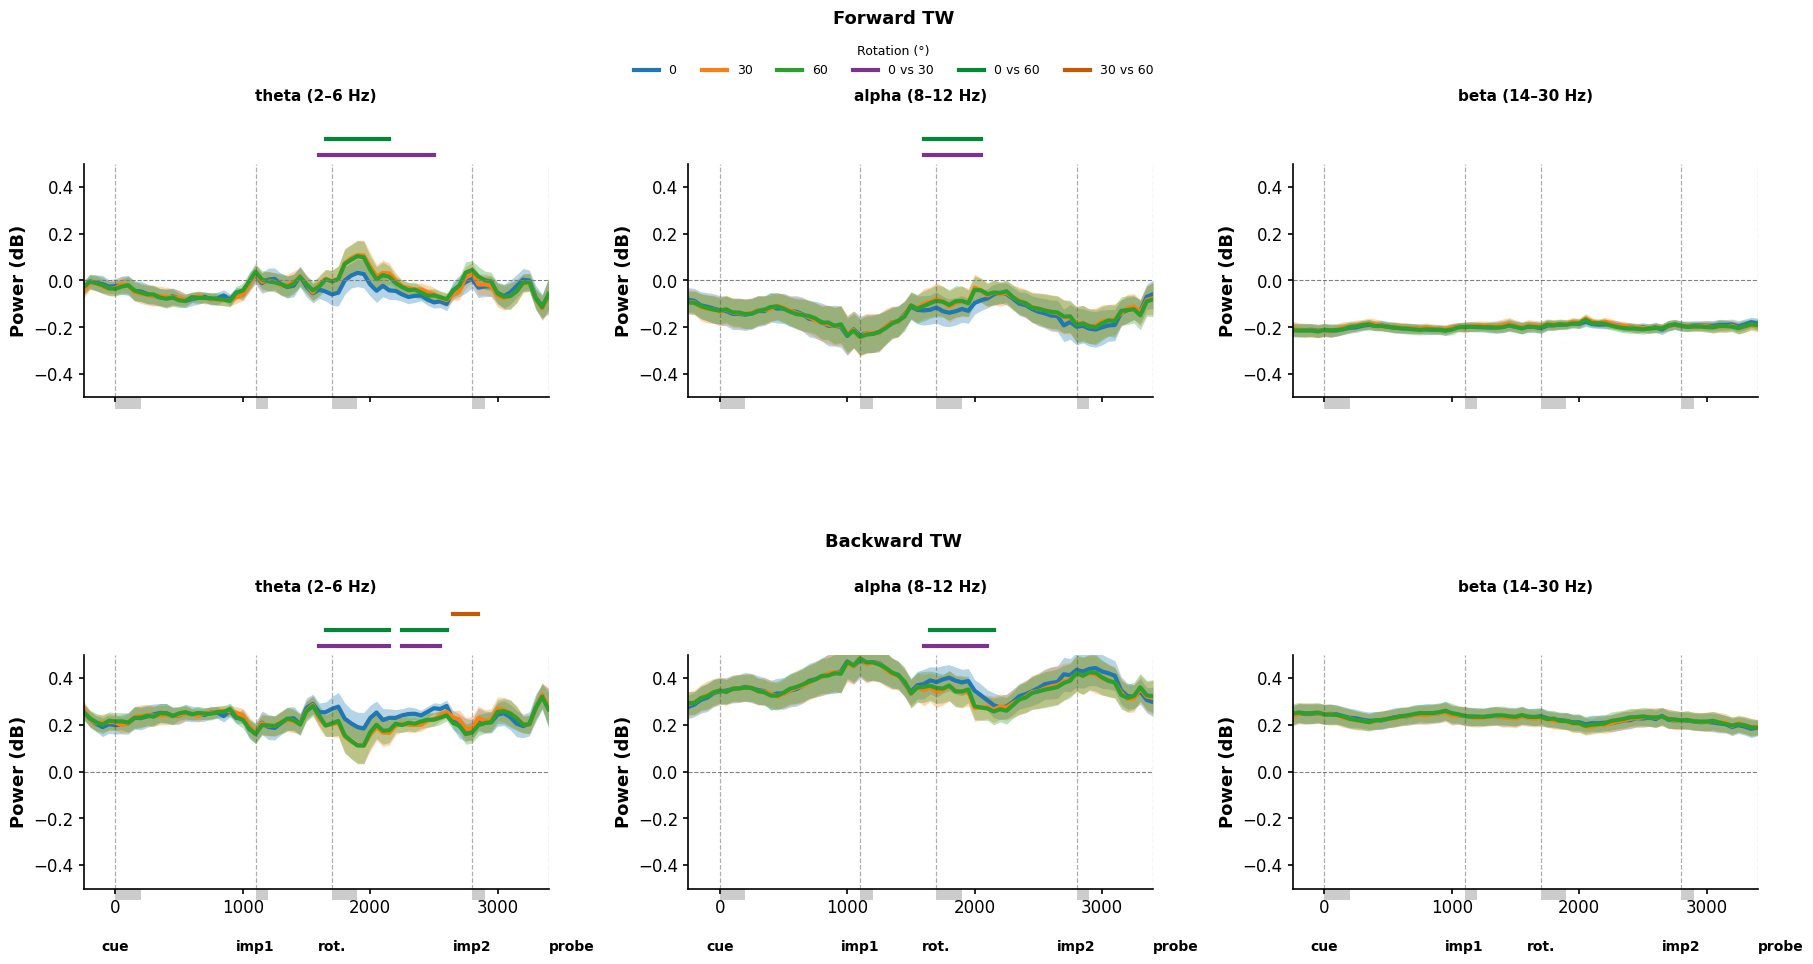

In [9]:
# Mean TW power across all 11 electrode lines, compared across rotation conditions.
rotation_power = plots.average_maps(kept, split_by='rotation', flip='cue_left')
plots.plot_band_timeseries(rotation_power,group='all_lines',legend_title='Rotation (°)',
    freq_bands=FREQ_BANDS,t_start=.5,t_stop=4.15,time_zero=.75,
    ylim=(-0.5, 0.5),tests=ROTATION_TESTS,bonferroni=True,
    colors={0:'#1f77b4',30:'#ff7f0e',60:'#2ca02c',  # rotation curves
            **dict(zip(ROTATION_TESTS,['#7b3294','#008837','#c45a00']))},  # difference bars
    panel_size=(7.2, 4.8),
    events=[(t, duration, label.replace('impulse ', 'imp').replace('rotation', 'rot.'))  # short labels
            for t, duration, label in EVENTS],
    n_perm=N_PERMUTATIONS, seed=SEED, alpha=ALPHA,
    output_dir=FIG_DIR,name='rotation_selected_lines')